# SAGAN and BigGAN: Attention and Conditional Scaling

## Theory, mathematics, and implementation context

Convolutional networks build local features, but distant regions interact only after many layers. Self-attention makes a direct global interaction. For features $X\in\mathbb R^{N\times C}$, SAGAN computes $Q=XW_q$, $K=XW_k$, $V=XW_v$, then $A=\mathrm{softmax}(QK^T/\sqrt d)$ and $Y=X+\gamma AV$. Initializing learnable $\gamma=0$ starts as an identity path. Attention costs $O(N^2)$ in spatial positions, so it is typically placed at modest resolutions.

BigGAN scaled conditional synthesis with class-conditioned normalization, shared class embeddings, spectral normalization, large batches, and a projection discriminator. The discriminator score adds image/class compatibility $f(x)^Te_y$ to its unconditional score. Truncation controls the fidelity-diversity trade-off. This notebook uses compact CIFAR-10 models to teach SAGAN attention and BigGAN conditioning; it does not reproduce original 128–512px training scale.

## Case study setup

In [1]:
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, utils
import matplotlib.pyplot as plt
torch.manual_seed(7)
DEVICE=torch.device("cuda" if torch.cuda.is_available() else "cpu")
tf=transforms.Compose([transforms.Resize(32),transforms.ToTensor(),transforms.Normalize((.5,)*3,(.5,)*3)])
ds=datasets.CIFAR10("./data",train=True,download=True,transform=tf)
loader=DataLoader(Subset(ds,range(4096)),batch_size=64,shuffle=True,num_workers=0,drop_last=True)
print(DEVICE,len(loader.dataset))

Files already downloaded and verified
cpu 4096


## SAGAN self-attention block

Keys are channel-reduced for efficiency. Query/source dimensions and the softmax axis are explicit.

In [2]:
class SelfAttention2d(nn.Module):
    def __init__(self,c):
        super().__init__(); h=max(8,c//8); self.q=nn.Conv2d(c,h,1); self.k=nn.Conv2d(c,h,1); self.v=nn.Conv2d(c,c,1); self.gamma=nn.Parameter(torch.zeros(()))
    def forward(self,x):
        b,c,h,w=x.shape; q=self.q(x).flatten(2).transpose(1,2); k=self.k(x).flatten(2); v=self.v(x).flatten(2).transpose(1,2)
        a=torch.softmax(torch.bmm(q,k)*q.shape[-1]**-.5,dim=-1)
        return x+self.gamma*torch.bmm(a,v).transpose(1,2).reshape(b,c,h,w)
print(SelfAttention2d(64)(torch.randn(2,64,8,8)).shape)

torch.Size([2, 64, 8, 8])


## Conditional BatchNorm and generator blocks

Class embeddings predict channel scale and shift. BigGAN uses richer shared embeddings and hierarchical latent injection; this version illustrates the conditioning principle.

In [3]:
class CBN(nn.Module):
    def __init__(self,c,nclass=10,edim=128):
        super().__init__(); self.bn=nn.BatchNorm2d(c,affine=False); self.emb=nn.Embedding(nclass,edim); self.scale=nn.Linear(edim,c); self.shift=nn.Linear(edim,c)
        nn.init.zeros_(self.scale.weight); nn.init.ones_(self.scale.bias); nn.init.zeros_(self.shift.weight); nn.init.zeros_(self.shift.bias)
    def forward(self,x,y): return self.bn(x)*self.scale(self.emb(y))[:,:,None,None]+self.shift(self.emb(y))[:,:,None,None]
class CBlock(nn.Module):
    def __init__(self,ci,co):
        super().__init__(); self.n1=CBN(ci); self.n2=CBN(co); self.c1=nn.Conv2d(ci,co,3,padding=1); self.c2=nn.Conv2d(co,co,3,padding=1); self.skip=nn.Conv2d(ci,co,1)
    def forward(self,x,y):
        u=F.interpolate(x,scale_factor=2,mode="nearest"); h=self.c1(F.relu(self.n1(u,y))); h=self.c2(F.relu(self.n2(h,y))); return h+self.skip(u)
class SAGANGenerator(nn.Module):
    def __init__(self):
        super().__init__(); self.fc=nn.Linear(128,128*4*4); self.blocks=nn.ModuleList([CBlock(128,64),CBlock(64,32),CBlock(32,16)]); self.attn=SelfAttention2d(32); self.rgb=nn.Conv2d(16,3,3,padding=1)
    def forward(self,z,y):
        x=self.fc(z).view(-1,128,4,4)
        for i,block in enumerate(self.blocks):
            x=block(x,y)
            if i==1: x=self.attn(x)
        return torch.tanh(self.rgb(F.relu(x)))
G=SAGANGenerator(); print(G(torch.randn(2,128),torch.tensor([0,1])).shape)


torch.Size([2, 3, 32, 32])


## BigGAN projection discriminator and spectral normalization

Spectral normalization controls the operator norm of discriminator layers. Projection conditioning adds compatibility between pooled image features and a class embedding.

In [4]:
from torch.nn.utils import spectral_norm
class ProjectionD(nn.Module):
    def __init__(self):
        super().__init__(); self.features=nn.Sequential(spectral_norm(nn.Conv2d(3,32,4,2,1)),nn.LeakyReLU(.2),spectral_norm(nn.Conv2d(32,64,4,2,1)),nn.LeakyReLU(.2),SelfAttention2d(64),spectral_norm(nn.Conv2d(64,128,4,2,1)),nn.LeakyReLU(.2))
        self.score=spectral_norm(nn.Linear(128,1)); self.embed=nn.Embedding(10,128)
    def forward(self,x,y):
        h=self.features(x).sum((2,3)); return self.score(h)+(self.embed(y)*h).sum(1,keepdim=True)
D=ProjectionD(); print(D(torch.randn(2,3,32,32),torch.tensor([1,2])).shape)


torch.Size([2, 1])


## Full training loop (run before sampling)

The previous version updated the models on only one batch, which is far too little for a GAN. This compact model now trains for 40 epochs on the same 4,096 CIFAR-10 images (2,560 update steps at batch size 64). The generator and discriminator are narrower to reduce runtime; attention remains at 8×8. On CPU this may take several minutes. Run this cell to completion before generating samples.


epoch 01/40 | D=2.160 | G=1.271 | 34.9s
epoch 02/40 | D=1.742 | G=0.871 | 42.6s
epoch 03/40 | D=1.668 | G=0.850 | 51.3s
epoch 04/40 | D=1.703 | G=0.762 | 46.3s
epoch 05/40 | D=1.591 | G=0.746 | 46.6s
epoch 06/40 | D=1.644 | G=0.713 | 42.2s
epoch 07/40 | D=1.651 | G=0.827 | 34.1s
epoch 08/40 | D=1.685 | G=0.856 | 24.5s
epoch 09/40 | D=1.741 | G=0.642 | 20.5s
epoch 10/40 | D=1.719 | G=0.687 | 15.1s
epoch 11/40 | D=1.700 | G=0.681 | 11.7s
epoch 12/40 | D=1.641 | G=0.603 | 11.3s
epoch 13/40 | D=1.655 | G=0.701 | 11.6s
epoch 14/40 | D=1.672 | G=0.710 | 11.9s
epoch 15/40 | D=1.619 | G=0.740 | 11.9s
epoch 16/40 | D=1.581 | G=0.760 | 12.4s
epoch 17/40 | D=1.573 | G=0.670 | 11.3s
epoch 18/40 | D=1.548 | G=0.727 | 11.4s
epoch 19/40 | D=1.485 | G=0.860 | 11.7s
epoch 20/40 | D=1.487 | G=0.919 | 11.6s
epoch 21/40 | D=1.498 | G=0.834 | 12.2s
epoch 22/40 | D=1.384 | G=0.871 | 11.4s
epoch 23/40 | D=1.330 | G=0.975 | 11.4s
epoch 24/40 | D=1.332 | G=0.877 | 11.3s
epoch 25/40 | D=1.307 | G=0.950 | 12.0s


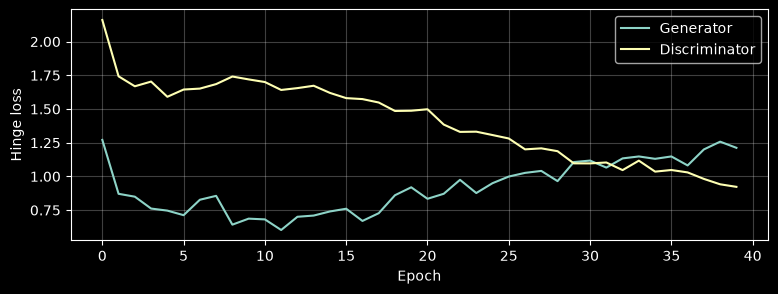

In [5]:
from IPython.display import clear_output
import time
LATENT_DIM=128
EPOCHS=40
G=SAGANGenerator().to(DEVICE); D=ProjectionD().to(DEVICE)
oG=torch.optim.Adam(G.parameters(),lr=2e-4,betas=(0,.999))
oD=torch.optim.Adam(D.parameters(),lr=2e-4,betas=(0,.999))
g_history=[]; d_history=[]
for epoch in range(EPOCHS):
    G.train(); D.train(); g_running=0.0; d_running=0.0; started=time.time()
    for x,y in loader:
        x=x.to(DEVICE); y=y.to(DEVICE); b=len(x)
        z=torch.randn(b,LATENT_DIM,device=DEVICE)
        fake=G(z,y).detach()
        d_loss=F.relu(1-D(x,y)).mean()+F.relu(1+D(fake,y)).mean()
        oD.zero_grad(set_to_none=True); d_loss.backward(); oD.step()
        for parameter in D.parameters(): parameter.requires_grad_(False)
        z=torch.randn(b,LATENT_DIM,device=DEVICE)
        g_loss=-D(G(z,y),y).mean()
        oG.zero_grad(set_to_none=True); g_loss.backward(); oG.step()
        for parameter in D.parameters(): parameter.requires_grad_(True)
        d_running+=d_loss.item(); g_running+=g_loss.item()
    d_history.append(d_running/len(loader)); g_history.append(g_running/len(loader))
    print(f"epoch {epoch+1:02d}/{EPOCHS} | D={d_history[-1]:.3f} | G={g_history[-1]:.3f} | {time.time()-started:.1f}s")
plt.figure(figsize=(9,3)); plt.plot(g_history,label="Generator"); plt.plot(d_history,label="Discriminator"); plt.xlabel("Epoch"); plt.ylabel("Hinge loss"); plt.legend(); plt.grid(alpha=.25)


## Truncation, attention cost, and scale

BigGAN truncation samples from a constrained latent distribution; radial clipping below is only an approximation. Holding z fixed and changing labels tests class control. At 32×32, full attention scores 1,024² positions; at 128×128, over 268 million scores per example. Truncation improves typicality at the cost of diversity.

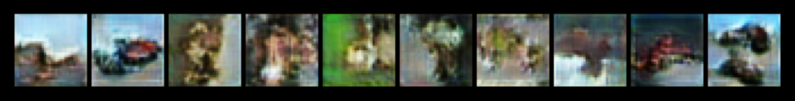

In [6]:
def truncate_z(z,threshold=2.0):
    # Coordinate-wise clipping is a simple approximation of BigGAN truncated sampling.
    return z.clamp(-threshold,threshold)
G.eval()
with torch.no_grad():
    z=truncate_z(torch.randn(10,128,device=DEVICE))
    labels=torch.arange(10,device=DEVICE)
    imgs=G(z,labels).cpu()
plt.figure(figsize=(10,2)); plt.axis("off"); plt.imshow(utils.make_grid(imgs,nrow=10,normalize=True).permute(1,2,0));


## Key Takeaways

- SAGAN uses global attention; zero initialization lets its residual path start as identity.
- BigGAN conditions G with class normalization and D with projection scores.
- Spectral normalization and hinge loss are common stability tools.
- Truncation trades variety for typicality.
- Attention has quadratic cost in spatial positions.
- BigGAN quality relied on substantial data and training scale.